(microbiome-analysis)=
# Exploring a soil microbiome in R

In this practical you will work in a group of three to explore a soil microbiome dataset and develop a question for a short presentation. Start with the data processing session, work through the core activities in the two microbiome practical sessions, and use your results in the group visualisation activity and mini-presentations. Share roles (coding, checking and interpreting) and rotate them so everyone takes part.

## Learning goals and preparation

By the end you should be able to inspect and wrangle a community dataset, use visualisations to explore patterns, and develop a testable hypothesis while recognising the limits of the data. You need a working knowledge of R. Revisit the data wrangling, data exploration and visualisation sections of [Data Management and Visualization in R](data-r.ipynb). Its advice to preserve the original data, document transformations, inspect distributions and choose informative graphics applies here too.

The core uses base R and needs no extra R package. Read this page in your browser and use RStudio to run the examples. In RStudio, select **File → New File → R Script**, save it as `code/microbiome_analysis.R` in the practical folder described below, and copy the code blocks into it in order. Place the cursor on a line and select **Run** (or select several lines and run them together). Keep the same R session open as you work: later commands use objects created earlier. The outputs on this page are examples; inspect your own results in RStudio's Console and Plots panes.

### Set up your files in RStudio

Use the MQB convention: `code/` holds scripts, `data/` holds the original input data and metadata, and `results/` holds generated figures and other outputs. Choose a practical folder and arrange it as follows:

```text
microbiome-practical/              ← working directory
├── code/
│   └── microbiome_analysis.R      ← your script
├── data/
│   └── microbiome/
│       ├── V.profile_bootstrap_cleaned_Oct18_ver4.csv
│       └── microbiome_metadata.md
└── results/                       ← figures and other outputs
```

1. Create the practical folder and its `code`, `data/microbiome` and `results` subfolders. Download the CSV and metadata using the links below and put them in `data/microbiome/`. Keep these original inputs unchanged.
2. In the RStudio **Console**, use `setwd()` to set the **practical folder**, not one of its subfolders, as your working directory. Replace the example path with the actual path to your folder:

   ```r
   setwd("/path/to/microbiome-practical")
   getwd()
   ```

   On Windows you can use forward slashes, for example `setwd("C:/Users/your-name/microbiome-practical")`. Check that `getwd()` displays your practical folder. Run `setwd()` again in the Console when you start a new R session if needed.
3. Create your R script in RStudio and save it as `code/microbiome_analysis.R`. Copy and run the examples in order, keeping the same R session open.
4. The import command below reads from `data/microbiome/` relative to the working directory; save your figures and other outputs in `results/`. If you choose a different location for the CSV, adjust the import path. Keep your computer-specific `setwd()` command in the Console rather than the shared script so that others can run the script from their own practical folder.

Alternatively, run `soil <- read.csv(file.choose())` in RStudio and select the CSV in `data/microbiome/`. Record where the file came from so the analysis remains reproducible.

## The question and the data

At Nash's Field, grassland soils have received different treatments, including lime and pesticides. The original practical asked whether bacterial communities in acidic environments might respond differently to pesticides from those in more neutral environments. Here we will explore patterns that might inspire questions for later study. Liming is a treatment, not a direct measurement of pH.

Download the [data CSV](../data/microbiome/V.profile_bootstrap_cleaned_Oct18_ver4.csv) and its {download}`metadata <../data/microbiome/microbiome_metadata.md>`. The data were provided by Prof. T. Bell, Imperial College London, who gave permission for publication. They come from the 2025–26 microbiome practical. Rows represent soil samples; the first six columns contain sample information and the remaining columns contain sequence counts for operational taxonomic units (OTUs).

Read the metadata before starting. Sequences were clustered into OTUs at 97% similarity. Counts are sequencing observations, not direct counts of organisms, and an OTU is not necessarily a species.

```{admonition} What we do not yet know
:class: caution
Plot identifiers, how depths relate to plots or cores, treatment allocation and replication, sequencing details and the exact rarefaction procedure are not yet available. The row number is not a confirmed plot identifier. Do not assume the rows are independent experimental replicates or infer causal treatment effects from these plots. We will update the documentation when this information becomes available.
```

## 1. Import and inspect

Read the CSV from `data/microbiome/` and keep the original data unchanged; add the commands to your script in `code/`. Inspect the data types, the size and a small part of the table. The blank first header becomes `X` when imported with `read.csv()` using its default settings.

In [1]:
soil <- read.csv("data/microbiome/V.profile_bootstrap_cleaned_Oct18_ver4.csv")
dim(soil)
names(soil)[1:12]
str(soil[, 1:6])
head(soil[, 1:6])

[1]   58 9688

[1] "X"           "Cide"        "Liming"      "Depth"       "Moisture"   
 [6] "ATP.biomass" "OTU100"      "OTU10000"    "OTU1001"     "OTU10010"   
[11] "OTU10021"    "OTU10027"

'data.frame':	58 obs. of  6 variables:
 $ X          : int  1 2 3 4 5 6 7 8 9 10 ...
 $ Cide       : chr  "Control" "Control" "Control" "Control" ...
 $ Liming     : chr  "limed" "limed" "limed" "limed" ...
 $ Depth      : int  1 2 3 4 5 1 2 3 4 5 ...
 $ Moisture   : int  26 25 25 25 19 33 33 19 20 15 ...
 $ ATP.biomass: num  NA 4.51 20.72 43.81 5.73 ...


,X,Cide,Liming,Depth,Moisture,ATP.biomass
,<int>,<chr>,<chr>,<int>,<int>,<dbl>
1,1,Control,limed,1,26,NA
2,2,Control,limed,2,25,4.514441
3,3,Control,limed,3,25,20.724364
4,4,Control,limed,4,25,43.805707
5,5,Control,limed,5,19,5.725536
6,6,Control,unlimed,1,33,132.117217


**Discuss:** What does one row represent? Which columns describe samples and which describe OTUs? Compare the answers with the metadata. How many missing values are there in each sample variable?

In [2]:
colSums(is.na(soil[, 1:6]))
table(soil$Cide, soil$Liming)
table(soil$Depth, soil$Liming)

X        Cide      Liming       Depth    Moisture ATP.biomass 
          0           0           0           0           0           3

         
          limed unlimed
  Control    10       9
  Insect      9      10
  Mollusc    10      10

   
    limed unlimed
  1     6       6
  2     6       5
  3     6       6
  4     6       6
  5     5       6

Counts in these tables are numbers of **samples**, not necessarily independent plots. Notice any unequal sample counts or missing values; consider how they affect a plot.

```{admonition} Ask an AI assistant: inspecting data
:class: tip
In the free ChatGPT or Gemini chat interface, paste your dimensions, column names and a small summary (not the entire CSV), then ask: “Explain R code for checking column types and missing values in this dataset. What should I inspect before plotting?”

**Check:** Run the suggestions, compare the output with the metadata, and explain to your group what each command does. A chatbot cannot see your R session unless you provide context.
```

## 2. Wrangle the sample and OTU data

Make separate objects for the metadata and the OTU counts, while retaining the original table. Check types, missing values, non-negative counts and row alignment. Avoid printing the whole OTU matrix.

In [3]:
sample_info <- soil[, 1:6]
otu <- soil[, -(1:6)]
stopifnot(nrow(sample_info) == nrow(otu), all(vapply(otu, is.numeric, logical(1))))
c(samples = nrow(otu), otus = ncol(otu), missing_counts = sum(is.na(otu)), negative_counts = sum(otu < 0, na.rm = TRUE))
head(otu[, 1:6])

samples            otus  missing_counts negative_counts 
             58            9682               0               0

,OTU100,OTU10000,OTU1001,OTU10010,OTU10021,OTU10027
,<int>,<int>,<int>,<int>,<int>,<int>
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,0,0,1,0,4,0
4,0,0,0,0,0,0
5,0,0,0,0,0,0
6,0,0,0,0,0,0


Each row in `sample_info` still corresponds to the same row in `otu`. Check this alignment whenever you filter or reorder data. Find OTUs with no recorded sequences in any sample. Retain the original object and create a separate analysis object.

In [4]:
zero_otus <- colSums(otu, na.rm = TRUE) == 0
sum(zero_otus)
otu_observed <- otu[, !zero_otus, drop = FALSE]
c(remaining_otus = ncol(otu_observed), samples = nrow(otu_observed))

[1] 452

remaining_otus        samples 
          9230             58

```{admonition} Ask an AI assistant: wrangling
:class: tip
Paste the dimensions and the first few column names, then ask: “Explain how to separate the first six metadata columns from the remaining OTU columns in R. How can I check that rows still match?”

**Check:** Compare the proposed dimensions and row order with the original. Explain the indexing to your group before using the code. Keep the original data unchanged.
```

### Explore sequencing totals and richness

The original practical says samples above approximately 5,000 sequences were subsampled. Inspect the actual totals below; the exact processing is still to be confirmed. Observed richness is the number of OTUs with a nonzero count in a sample. It is influenced by sequencing and does not measure all organisms present.

   sequences       richness     
 Min.   :4870   Min.   : 226.0  
 1st Qu.:4936   1st Qu.: 841.8  
 Median :4964   Median :1057.5  
 Mean   :4956   Mean   :1018.8  
 3rd Qu.:4978   3rd Qu.:1284.0  
 Max.   :5000   Max.   :1568.0  

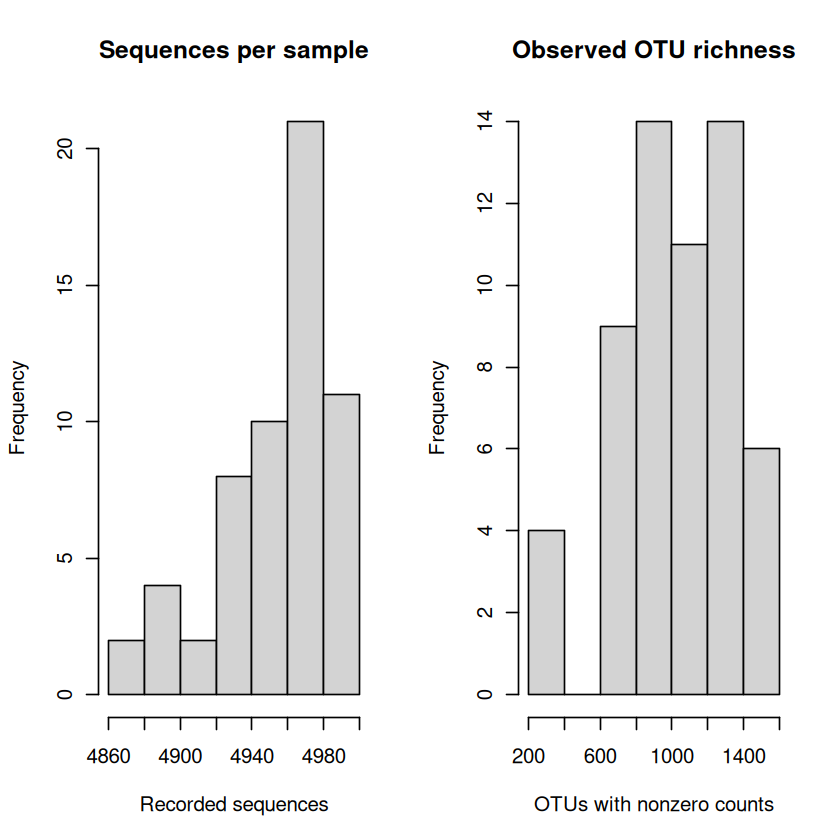

In [5]:
sample_info$sequences <- rowSums(otu_observed)
sample_info$richness <- rowSums(otu_observed > 0)
summary(sample_info[, c("sequences", "richness")])
par(mfrow = c(1, 2))
hist(sample_info$sequences, main = "Sequences per sample", xlab = "Recorded sequences")
hist(sample_info$richness, main = "Observed OTU richness", xlab = "OTUs with nonzero counts")
par(mfrow = c(1, 1))

**Discuss:** What do the distributions look like? Are sample sequencing totals equal? How might sequencing depth affect observed richness? A sample accumulation curve and a sequence rarefaction curve answer different questions; this exercise does not establish that all diversity has been sampled.

```{admonition} Sequencing and sampling caveat
:class: caution
The counts have already undergone processing and approximate subsampling, but the details are incomplete. Differences in richness may reflect sampling and sequencing as well as biology. Zeros mean no recorded sequences, not certain absence.
```

## 3. Explore patterns visually

Begin with a simple plot, then try another grouping or a different visual representation. Individual points show the distribution more directly than means alone. Depth values are ordered categories, not known physical depths. The code below makes depth categorical for display.

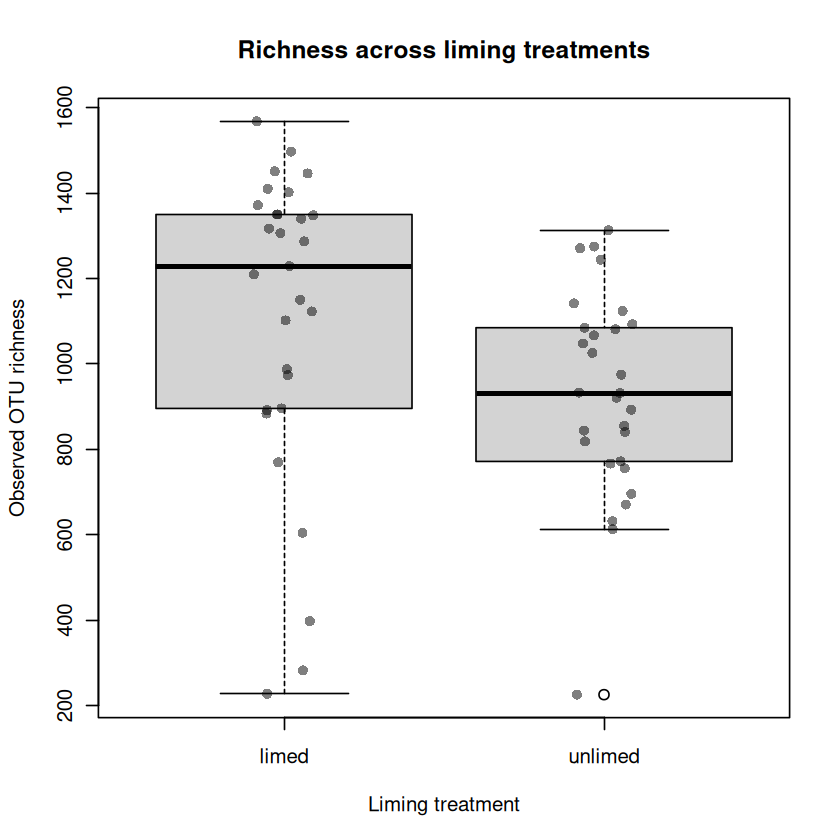

In [6]:
sample_info$Depth <- factor(sample_info$Depth, levels = 1:5, ordered = TRUE)
boxplot(richness ~ Liming, data = sample_info,
        xlab = "Liming treatment", ylab = "Observed OTU richness",
        main = "Richness across liming treatments")
stripchart(richness ~ Liming, data = sample_info, vertical = TRUE,
           method = "jitter", pch = 16, col = rgb(0, 0, 0, 0.5), add = TRUE)

**Group task:** Make at least two exploratory plots, for example richness by pesticide treatment or depth, or moisture versus richness coloured by liming. Consider whether a log scale would help for a skewed positive variable. Label axes with meaningful names and units where known; show individual observations and make legends readable. Add your plotting commands to your script in `code/`. Compare plots and describe a pattern and a counterexample or uncertainty.

```{admonition} Comparisons are exploratory
:class: caution
Samples may share plots or cores and the allocation and replication of treatments are unknown. Differences between groups in a figure are descriptive; they do not establish treatment effects. Depth category is not a measured depth in centimetres, and liming is not a measured pH.
```

```{admonition} Ask an AI assistant: choosing a plot
:class: tip
Tell ChatGPT or Gemini your question, the variables and their types, and a small summary of the data. Ask: “Suggest two R plot types for exploring this question, and explain what each could hide.”

**Check:** Make and compare the plots. Inspect individual observations, missing values, labels, scales and the metadata. Decide as a group which plot best answers your question and why.
```

### Optional: another measurement

ATP is described as an indicator of microbial metabolic activity; its units and measurement details are unavailable. Check missing and positive values before exploring a logarithmic axis. A log scale can make skewed positive values easier to see, but does not automatically validate a model.

[1] 3

[1] 0

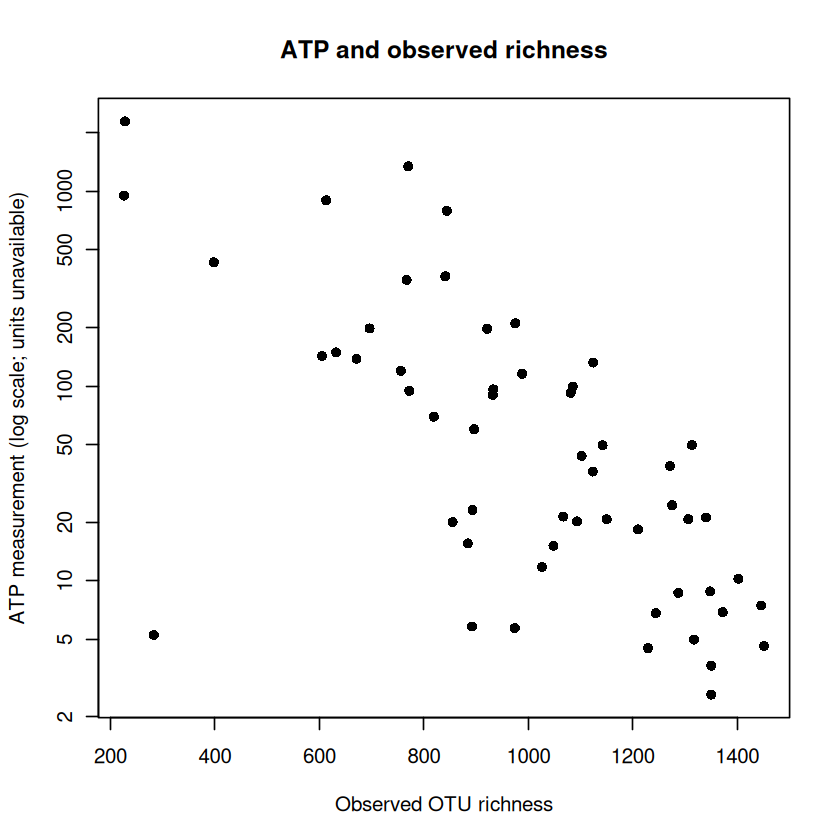

In [7]:
sum(is.na(sample_info$ATP.biomass))
sum(sample_info$ATP.biomass <= 0, na.rm = TRUE)
atp_ok <- !is.na(sample_info$ATP.biomass) & sample_info$ATP.biomass > 0
plot(sample_info$richness[atp_ok], sample_info$ATP.biomass[atp_ok], log = "y",
     xlab = "Observed OTU richness", ylab = "ATP measurement (log scale; units unavailable)",
     main = "ATP and observed richness", pch = 16)

**Discuss:** How many samples are excluded from this plot? Does an association establish that richness determines ATP? What other explanations or missing information matter?

```{admonition} Ask an AI assistant: debugging
:class: tip
If a command fails, paste the shortest relevant code, the exact error and a small description such as `str(sample_info)` into ChatGPT or Gemini. Ask: “Explain the likely cause and suggest a small correction.”

**Check:** Test the correction, inspect the output and explain why it works. Do not paste the entire dataset or accept a fix you cannot understand.
```

## 4. From patterns to hypotheses

Choose one pattern from your exploratory figures. Write (1) an observation describing what is visible, (2) at least two plausible explanations, and (3) a testable hypothesis for a future study. Specify what you would measure and what pattern the hypothesis predicts. Consider other variables, missing design information and alternative explanations. Exploring many plots can produce patterns by chance, so treat your hypothesis as a starting point rather than a confirmed result.

```{admonition} Ask an AI assistant: developing ideas
:class: tip
Describe your observed pattern, the variables and the known design gaps. Ask ChatGPT or Gemini: “Suggest two alternative explanations and a testable follow-up hypothesis. Separate observations from speculation.”

**Check:** Does each suggestion follow from the figure and metadata? The chatbot cannot recover missing plot identifiers or replication. Check biological claims against reliable sources and choose a hypothesis your group can explain.
```

### Save a figure in `results/`

Add figure-export commands to your script in `code/` so you can recreate the file. For example, with the practical folder as the working directory, the following creates a PNG in `results/`. The seed makes the jittered point positions reproducible. Run the whole block together; `dev.off()` closes the file. Adapt the plot and filename for your own group figure.

In [8]:
png("results/richness_by_liming.png", width = 1200, height = 900, res = 150)
boxplot(richness ~ Liming, data = sample_info,
        xlab = "Liming treatment", ylab = "Observed OTU richness",
        main = "Richness across liming treatments")
set.seed(42)
stripchart(richness ~ Liming, data = sample_info, vertical = TRUE,
           method = "jitter", pch = 16, col = rgb(0, 0, 0, 0.5), add = TRUE)
dev.off()

agg_record_1f9e939360474 
                       2

## 5. Group figure and mini-presentation

For the data visualisation group activity, prepare a short presentation with:

1. Your question and the variables used.
2. One clearly labelled figure, including a legend if needed and the observations or sample counts where useful.
3. What the figure shows, including variability and any missing or excluded values.
4. A testable hypothesis, an alternative explanation and a possible follow-up measurement or study.
5. The key design and sequencing limitations that prevent stronger conclusions.

Each group member should be ready to explain part of the work. Save the code used to produce the figure in `code/microbiome_analysis.R` and the finished figure in `results/`, so that the group can reproduce and use it in the presentation; consult the `data-r` chapter for figure design and export.

```{admonition} Ask an AI assistant: presentation feedback
:class: tip
Paste your question, figure labels and a short description of the pattern into ChatGPT or Gemini. Ask: “What might confuse an audience, and where does this interpretation go beyond the observations?”

**Check:** Compare the feedback with your plot and metadata. Revise the figure and wording yourselves; your group is responsible for the interpretation and caveats.
```